Mounted at /content/drive
Dataset loaded successfully.
Starting Nested LOSO CV for 4 users...

--- Processing Fold: Held-out User [debora] ---


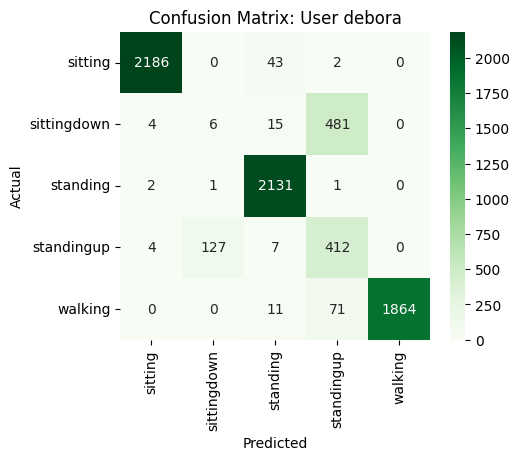

--- Processing Fold: Held-out User [jose_carlos] ---


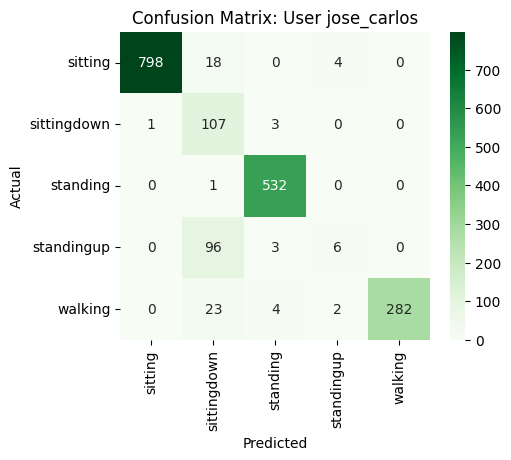

--- Processing Fold: Held-out User [katia] ---


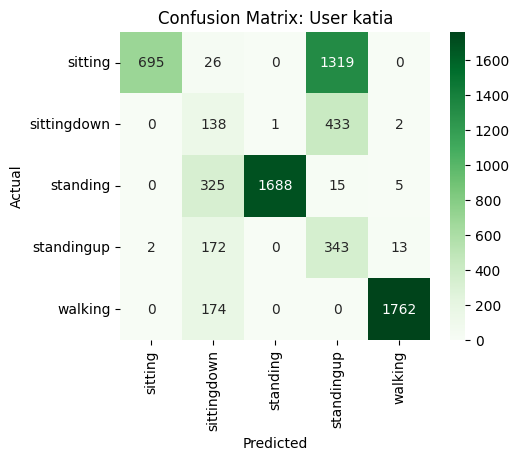

--- Processing Fold: Held-out User [wallace] ---


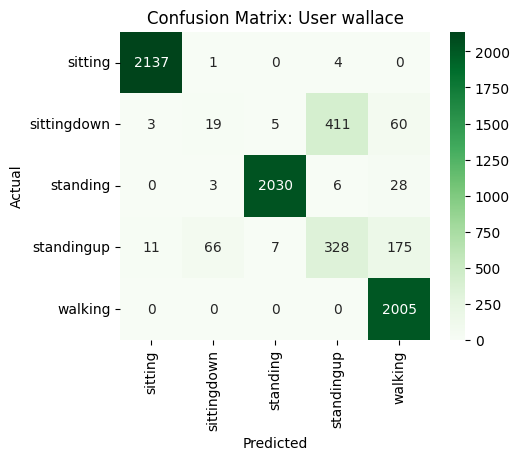

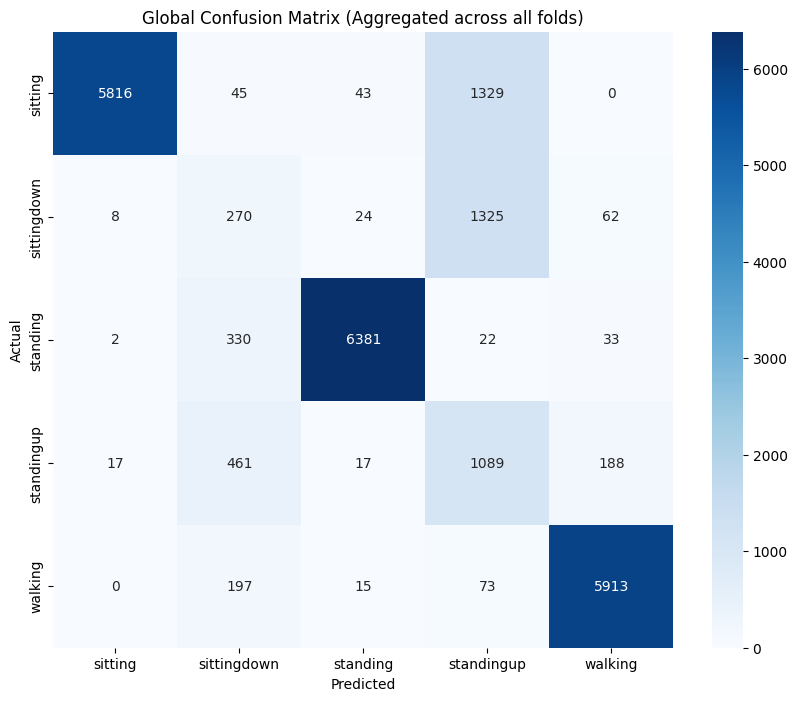

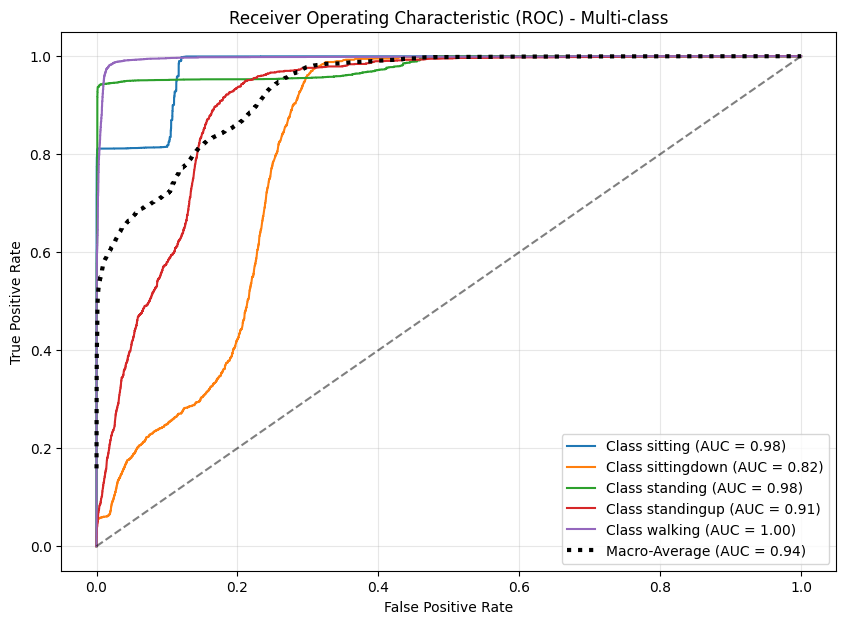

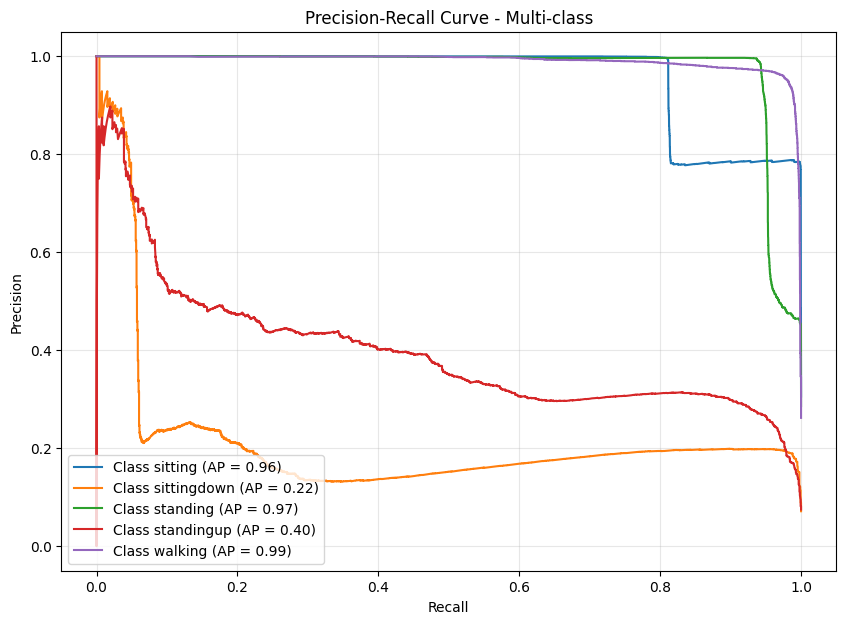


FINAL NESTED LOSO RESULTS
       User  F1-Score
     debora  0.883727
jose_carlos  0.909139
      katia  0.698042
    wallace  0.873672
--------------------------------------------------
Mean F1-Score: 0.8411
--------------------------------------------------

Global Classification Report:
              precision    recall  f1-score   support

     sitting       1.00      0.80      0.89      7233
 sittingdown       0.21      0.16      0.18      1689
    standing       0.98      0.94      0.96      6768
  standingup       0.28      0.61      0.39      1772
     walking       0.95      0.95      0.95      6198

    accuracy                           0.82     23660
   macro avg       0.69      0.70      0.68     23660
weighted avg       0.87      0.82      0.84     23660



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, precision_recall_curve,
                             average_precision_score, classification_report)
from sklearn.model_selection import RandomizedSearchCV, LeaveOneGroupOut
from sklearn.preprocessing import label_binarize

# 1. Mount Google Drive and Load Data
drive.mount('/content/drive')
dataset_path = '/content/drive/MyDrive/Colab/windowed.csv'

try:
    df = pd.read_csv(dataset_path)
    windowed_df = df.copy()
    X = windowed_df.drop(columns=['class', 'user'])
    y = windowed_df['class']
    groups = windowed_df['user']
    classes = np.unique(y)
    n_classes = len(classes)
    print("Dataset loaded successfully.")
except Exception as e:
    print(f"Error loading dataset: {e}")
    windowed_df = None

if windowed_df is not None:
    # 2. Hyperparameter Space Configuration
    param_dist_rf = {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5, 10],
        'max_features': ['sqrt', 'log2'],
        'bootstrap': [True]
    }

    loso = LeaveOneGroupOut()

    # Lists to store global results for aggregation
    all_y_true = []
    all_y_pred = []
    all_y_proba = []
    fold_summaries = []

    print(f"Starting Nested LOSO CV for {len(np.unique(groups))} users...\n")

    # 3. Manual Nested LOSO Loop
    for train_idx, test_idx in loso.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        held_out_user = groups.iloc[test_idx].unique()[0]

        print(f"--- Processing Fold: Held-out User [{held_out_user}] ---")

        # Inner CV for hyperparameter tuning
        inner_cv = 3
        random_search = RandomizedSearchCV(
            estimator=RandomForestClassifier(random_state=42),
            param_distributions=param_dist_rf,
            n_iter=10,
            cv=inner_cv,
            scoring='f1_weighted',
            n_jobs=-1,
            verbose=0
        )

        random_search.fit(X_train, y_train)
        best_model = random_search.best_estimator_

        # Predictions
        y_pred = best_model.predict(X_test)
        y_proba = best_model.predict_proba(X_test)

        # Calculate F1 for this specific user
        f1 = f1_score(y_test, y_pred, average='weighted')

        # Store data for global analysis
        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)
        all_y_proba.extend(y_proba)
        fold_summaries.append({'User': held_out_user, 'F1-Score': f1})

        # Display Individual Confusion Matrix for this user
        cm_user = confusion_matrix(y_test, y_pred, labels=classes)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm_user, annot=True, fmt='d', cmap='Greens',
                    xticklabels=classes, yticklabels=classes)
        plt.title(f'Confusion Matrix: User {held_out_user}')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.show()

    # Convert accumulated lists to arrays
    all_y_true = np.array(all_y_true)
    all_y_pred = np.array(all_y_pred)
    all_y_proba = np.array(all_y_proba)

    # Binarize labels for multi-class ROC/PR curves
    y_true_bin = label_binarize(all_y_true, classes=classes)

    # --- FINAL VISUALIZATIONS ---

    # 1. Global Confusion Matrix
    plt.figure(figsize=(10, 8))
    cm_total = confusion_matrix(all_y_true, all_y_pred, labels=classes)
    sns.heatmap(cm_total, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    plt.title('Global Confusion Matrix (Aggregated across all folds)')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    # 2. ROC Curves (Per Class + Macro Average)
    plt.figure(figsize=(10, 7))
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], all_y_proba[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        plt.plot(fpr[i], tpr[i], label=f'Class {classes[i]} (AUC = {roc_auc[i]:.2f})')

    # Calculate Macro-Average ROC
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    plt.plot(all_fpr, mean_tpr, label=f'Macro-Average (AUC = {auc(all_fpr, mean_tpr):.2f})',
             color='black', linestyle=':', linewidth=3)

    plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    plt.title('Receiver Operating Characteristic (ROC) - Multi-class')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.show()

    # 3. Precision-Recall Curves (Per Class + Mean)
    plt.figure(figsize=(10, 7))
    for i in range(n_classes):
        precision, recall, _ = precision_recall_curve(y_true_bin[:, i], all_y_proba[:, i])
        avg_p = average_precision_score(y_true_bin[:, i], all_y_proba[:, i])
        plt.plot(recall, precision, label=f'Class {classes[i]} (AP = {avg_p:.2f})')

    plt.title('Precision-Recall Curve - Multi-class')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.legend(loc='lower left')
    plt.grid(alpha=0.3)
    plt.show()

    # --- FINAL SUMMARY ---
    print("\n" + "="*50)
    print("FINAL NESTED LOSO RESULTS")
    print("="*50)
    results_df = pd.DataFrame(fold_summaries)
    print(results_df.to_string(index=False))
    print("-" * 50)
    print(f"Mean F1-Score: {results_df['F1-Score'].mean():.4f}")
    print("-" * 50)
    print("\nGlobal Classification Report:")
    print(classification_report(all_y_true, all_y_pred))